# Simulating the uncertainty of sample correlation estimator

Assume that we want to examine the properties of the sample covariance estimator, in particular we want to look at the distribution of the correlations. We assume the correlation matrix $\boldsymbol{C}$

$$
\boldsymbol{C} = \begin{pmatrix} 1 & \rho & \rho  & \rho & \rho \\
\rho & 1 & \rho  & \rho & \rho \\
\rho & \rho & 1  & \rho & \rho \\
\rho & \rho & \rho  & 1 & \rho \\
\rho & \rho & \rho  & \rho & 1 \end{pmatrix}
$$

In [1]:
# import numpy for working with matrices
import numpy as np

# import matplotlib for plotting
import matplotlib.pyplot as plt

## Problem 1

Assume $\rho = 0.5$ and that the data generating process is normal 

$$
\mathbf{X} \sim N(\mathbf{0}, \boldsymbol{C})
$$

Simulate $N=25$ observations $10\;000$ times and plot the histogram of the correlation estimates for the first and second variable. 


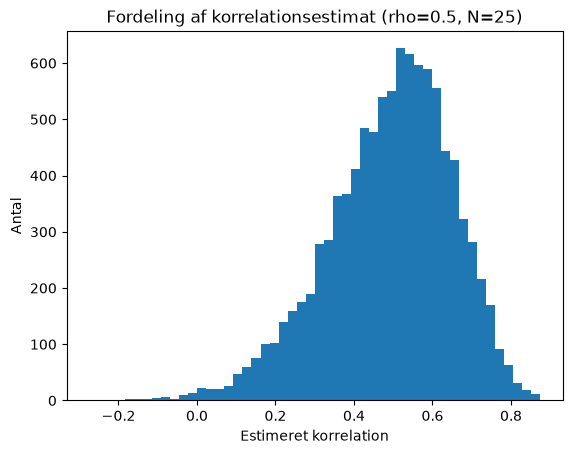

In [4]:
rho = 0.5
n_vars = 5
N = 25
n_sim = 10000

# byg korrelationsmatrix: rho overalt, 1 på diagonalen
C = np.full((n_vars, n_vars), rho)
np.fill_diagonal(C, 1.0)

# gem alle 10.000 estimater her
correlations = np.zeros(n_sim)

for i in range(n_sim):
    # træk 25 observationer fra 5-dimensional normalfordeling
    X = np.random.multivariate_normal(mean=np.zeros(n_vars), cov=C, size=N)
    
    # beregn den estimerede korrelationsmatrix ud fra de 25 observationer
    corr_matrix = np.corrcoef(X, rowvar=False)
    
    # gem korrelationen mellem variabel 1 og 2
    correlations[i] = corr_matrix[0, 1]

# plot histogram
plt.hist(correlations, bins=50)
plt.xlabel('Estimeret korrelation')
plt.ylabel('Antal')
plt.title('Fordeling af korrelationsestimat (rho=0.5, N=25)')
plt.show()

**Tolkning:** Med kun N=25 observationer varierer det estimerede korrelationskoefficient betydeligt omkring den sande værdi på 0.5 — fra under 0 til over 0.8 i 10.000 simuleringer. Dette illustrerer at sample-korrelation er et meget usikkert estimat ved små stikprøvestørrelser, selvom det i gennemsnit rammer den korrekte værdi (0.5).

## Problem 2

What happens if we increase $\rho$?

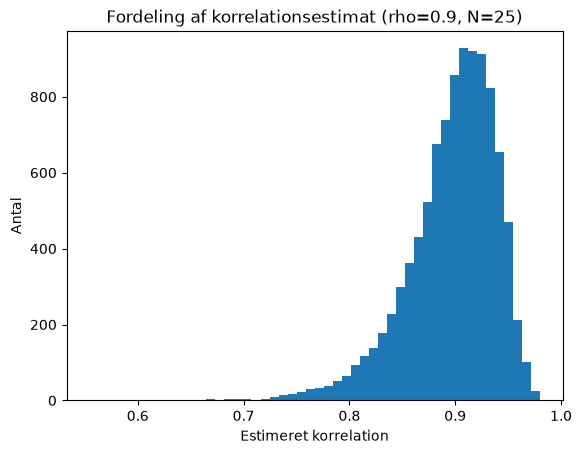

In [5]:
rho = 0.9   # <-- ændret fra 0.5 til 0.9
n_vars = 5
N = 25
n_sim = 10000

C = np.full((n_vars, n_vars), rho)
np.fill_diagonal(C, 1.0)

correlations_high_rho = np.zeros(n_sim)

for i in range(n_sim):
    X = np.random.multivariate_normal(mean=np.zeros(n_vars), cov=C, size=N)
    corr_matrix = np.corrcoef(X, rowvar=False)
    correlations_high_rho[i] = corr_matrix[0, 1]

plt.hist(correlations_high_rho, bins=50)
plt.xlabel('Estimeret korrelation')
plt.ylabel('Antal')
plt.title('Fordeling af korrelationsestimat (rho=0.9, N=25)')
plt.show()

**Tolkning:** Med rho=0.9 er fordelingen af korrelationsestimatet betydeligt smallere end med rho=0.5, og desuden skæv i stedet for symmetrisk. Det skyldes at korrelation er begrænset til intervallet [-1,1] — jo tættere den sande korrelation er på grænsen, jo mindre plads er der for estimatet at variere opad, hvilket "presser" fordelingen sammen og gør den asymmetrisk.

## Problem 3

What happens if you apply the [Fisher transformation](https://en.wikipedia.org/wiki/Fisher_transformation) $z = \frac{1}{2} \ln \frac{1 + \hat{\rho}}{1 - \hat{\rho}} = \text{artanh}(\hat{\rho})$?

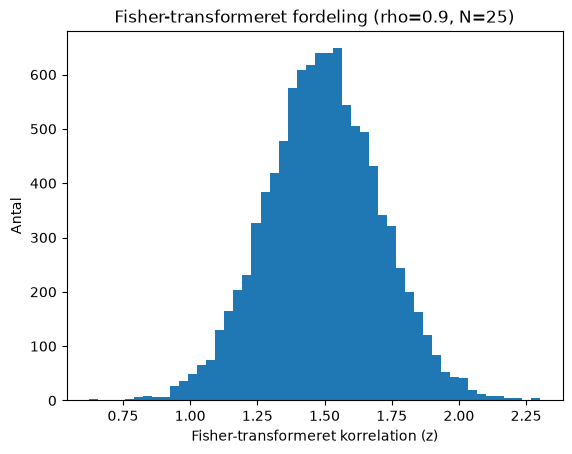

In [6]:
# anvend Fisher-transformationen
z = np.arctanh(correlations_high_rho)

plt.hist(z, bins=50)
plt.xlabel('Fisher-transformeret korrelation (z)')
plt.ylabel('Antal')
plt.title('Fisher-transformeret fordeling (rho=0.9, N=25)')
plt.show()

**Tolkning:** Efter Fisher-transformationen bliver fordelingen langt mere symmetrisk og klokkeformet sammenlignet med den rå, skæve korrelationsfordeling fra Problem 2. Dette bekræfter at Fisher-transformationen effektivt fjerner skævheden forårsaget af korrelationens grænser ved ±1, hvilket gør z tilnærmelsesvis normalfordelt — nyttigt hvis man ønsker at anvende statistiske metoder (fx konfidensintervaller), der antager normalfordelte data.